<a href="https://colab.research.google.com/github/fauzia-annisa/DIscovery-Engine-Recsys.ipynb./blob/main/DIscovery_Engine_Recsys_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1: settup

In [ ]:
!pip -q install kagglehub lightgbm faiss-cpu
import os, time, json, re, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy.sparse as sp
import torch, torch.nn as nn, torch.nn.functional as F
warnings.filterwarnings("ignore")
SEED = 42; np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("src", exist_ok=True); os.makedirs("artifacts", exist_ok=True)
print(device)

cpu


2: the model file (shared with your demo app later)

In [ ]:
%%writefile src/model.py
import re, torch, torch.nn as nn, torch.nn.functional as F

GENRES = ["Action","Adventure","Animation","Children's","Comedy","Crime","Documentary","Drama","Fantasy",
          "Film-Noir","Horror","Musical","Mystery","Romance","Sci-Fi","Thriller","War","Western"]
AGE_MAP = {1:0, 18:1, 25:2, 35:3, 45:4, 50:5, 56:6}

def parse_year(t):
    m = re.search(r"\((\d{4})\)\s*$", t); return int(m.group(1)) if m else 1990
def year_bucket(y): return int(min(max((y - 1915)//5, 0), 17))

class TwoTower(nn.Module):
    # index n_users / n_items = reserved UNKNOWN id, trained by id-dropout (handles cold start)
    def __init__(self, n_users, n_items, n_genres=18, n_age=7, n_occ=21, n_year=18, dim=64):
        super().__init__()
        self.user_id = nn.Embedding(n_users+1, dim); self.gender = nn.Embedding(2, 4)
        self.age = nn.Embedding(n_age, 8); self.occ = nn.Embedding(n_occ, 8)
        self.user_mlp = nn.Sequential(nn.Linear(dim+20, 256), nn.ReLU(), nn.Linear(256, dim))
        self.item_id = nn.Embedding(n_items+1, dim); self.year = nn.Embedding(n_year, 8)
        self.genre_proj = nn.Linear(n_genres, 16)
        self.item_mlp = nn.Sequential(nn.Linear(dim+24, 256), nn.ReLU(), nn.Linear(256, dim))
        for e in (self.user_id, self.item_id): nn.init.normal_(e.weight, std=0.05)
    def user_vec(self, uid, g, a, o):
        x = torch.cat([self.user_id(uid), self.gender(g), self.age(a), self.occ(o)], -1)
        return F.normalize(self.user_mlp(x), dim=-1)
    def item_vec(self, iid, genres, year):
        x = torch.cat([self.item_id(iid), self.year(year), F.relu(self.genre_proj(genres))], -1)
        return F.normalize(self.item_mlp(x), dim=-1)

Writing src/model.py


3: load the data

(1000209, 4) 6040 3706


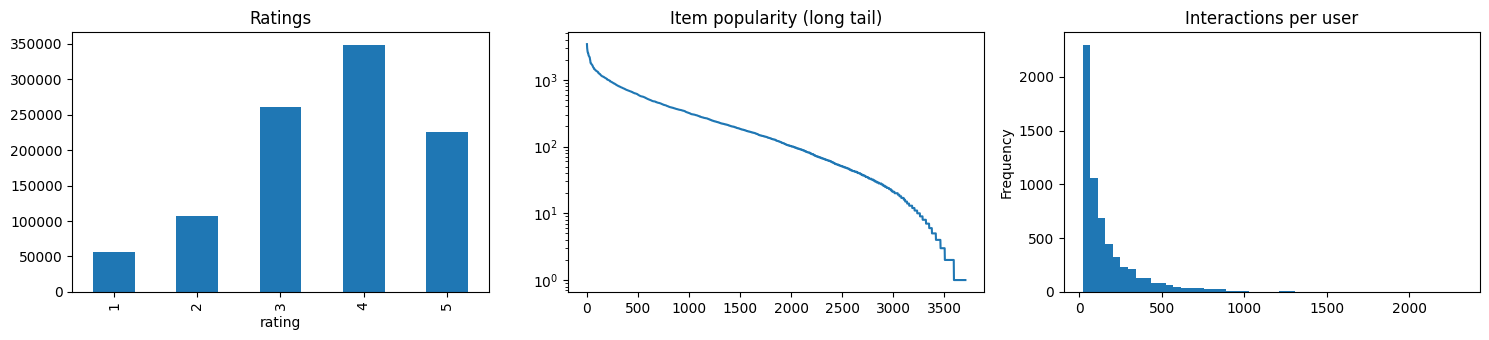

In [ ]:
if not os.path.exists("ml-1m"):
    !wget -q https://files.grouplens.org/datasets/movielens/ml-1m.zip
    !unzip -q -o ml-1m.zip
kw = dict(sep="::", engine="python", encoding="latin-1")
ratings = pd.read_csv("ml-1m/ratings.dat", names=["user","item","rating","ts"], **kw)
movies  = pd.read_csv("ml-1m/movies.dat",  names=["item","title","genres"], **kw)
users   = pd.read_csv("ml-1m/users.dat",   names=["user","gender","age","occupation","zip"], **kw)
print(ratings.shape, ratings.user.nunique(), ratings.item.nunique())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ratings.rating.value_counts().sort_index().plot.bar(ax=ax[0], title="Ratings")
ratings.item.value_counts().reset_index(drop=True).plot(ax=ax[1], logy=True, title="Item popularity (long tail)")
ratings.groupby("user").size().plot.hist(ax=ax[2], bins=50, title="Interactions per user")
plt.tight_layout(); plt.show()

4: time-based split (no leakage)

In [ ]:
pos = ratings[ratings.rating >= 4].sort_values(["user","ts","item"]).copy()
pos = pos[pos.groupby("user").item.transform("count") >= 5].copy()
pos["r"] = pos.groupby("user").cumcount(ascending=False)        # 0 = most recent

movies_s = movies.sort_values("item").reset_index(drop=True)
user_ids = np.sort(pos.user.unique()); uid_map = {u:k for k,u in enumerate(user_ids)}
item_ids = movies_s.item.values;       iid_map = {m:k for k,m in enumerate(item_ids)}
nU, nI = len(user_ids), len(item_ids)
pos["u"] = pos.user.map(uid_map); pos["i"] = pos.item.map(iid_map)

train_df, val_df, test_df = pos[pos.r>=2].copy(), pos[pos.r==1].copy(), pos[pos.r==0].copy()
def to_csr(df): return sp.csr_matrix((np.ones(len(df), dtype=np.float32), (df.u.values, df.i.values)), shape=(nU, nI))
X_train = to_csr(train_df)
seen_val_mask  = X_train.toarray() > 0
seen_test_mask = seen_val_mask | (to_csr(val_df).toarray() > 0)
val_target  = np.zeros(nU, int); val_target[val_df.u.values]   = val_df.i.values
test_target = np.zeros(nU, int); test_target[test_df.u.values] = test_df.i.values
item_cnt = np.asarray(X_train.sum(0)).ravel(); user_n = np.asarray(X_train.sum(1)).ravel()
print(f"users={nU} items={nI} train={len(train_df)} val={len(val_df)} test={len(test_df)}")
print("items unseen in train (item cold start):", int((item_cnt == 0).sum()))

users=6034 items=3883 train=563204 val=6034 test=6034
items unseen in train (item cold start): 358


5: user and item features

In [ ]:
from src.model import TwoTower, GENRES, AGE_MAP, parse_year, year_bucket
gidx = {g:k for k,g in enumerate(GENRES)}
item_genres = np.zeros((nI, 18), np.float32)
for k, gs in enumerate(movies_s.genres):
    for g in gs.split("|"):
        if g in gidx: item_genres[k, gidx[g]] = 1
item_year_b = np.array([year_bucket(parse_year(t)) for t in movies_s.title])
us = users.set_index("user").loc[user_ids]
g_np = (us.gender == "M").astype(int).values
a_np = us.age.map(AGE_MAP).values
o_np = us.occupation.values

6: metrics and popularity baseline

In [ ]:
def rank_and_top(S, mask, target, K=10):
    S = np.array(S, dtype=np.float32, copy=True); S[mask] = -np.inf
    ts = S[np.arange(nU), target]
    rank = (S > ts[:,None]).sum(1) + ((S == ts[:,None]).sum(1) - 1) / 2.0   # expected rank under ties
    top = np.argpartition(-S, K, axis=1)[:, :K]
    return rank, top
def eval_split(S, split="test"):
    return rank_and_top(S, *( (seen_test_mask, test_target) if split=="test" else (seen_val_mask, val_target) ))
def ndcg_vec(r, K=10): return np.where(r < K, 1/np.log2(r+2), 0.0)
def summarize(r, top):
    return {"Recall@10": (r<10).mean(), "Recall@50": (r<50).mean(),
            "NDCG@10": ndcg_vec(r).mean(), "Coverage@10": len(np.unique(top))/nI}

RANK, TOP = {}, {}
def register(name, S=None, rank=None, top=None):
    if S is not None: rank, top = eval_split(S, "test")
    RANK[name], TOP[name] = rank, top
    return summarize(rank, top)

S_pop = np.tile(item_cnt.astype(np.float32), (nU, 1))
print("Popularity:", register("Popularity", S_pop))

Popularity: {'Recall@10': np.float64(0.039277427908518396), 'Recall@50': np.float64(0.12877030162412992), 'NDCG@10': np.float64(0.019286970881375678), 'Coverage@10': 0.029616276075199587}


7: item-KNN and SVD baselines

In [ ]:
co = (X_train.T @ X_train).toarray(); nrm = np.sqrt(np.diag(co))
sim = co / (np.outer(nrm, nrm) + 10.0); np.fill_diagonal(sim, 0)
S_knn = np.asarray(X_train @ sim, dtype=np.float32)
print("ItemKNN:", register("ItemKNN", S_knn))

from sklearn.decomposition import TruncatedSVD
best = (-1, None)
for k in [16, 32, 64, 128]:
    svd = TruncatedSVD(k, random_state=SEED); Sk = (svd.fit_transform(X_train) @ svd.components_).astype(np.float32)
    nd = ndcg_vec(eval_split(Sk, "val")[0]).mean(); print(f"  SVD k={k} val NDCG@10={nd:.4f}")
    if nd > best[0]: best = (nd, Sk)
S_svd = best[1]; print("SVD:", register("SVD", S_svd))

ItemKNN: {'Recall@10': np.float64(0.05187272124627113), 'Recall@50': np.float64(0.17732847199204507), 'NDCG@10': np.float64(0.026326050110607898), 'Coverage@10': 0.08575843420036054}
  SVD k=16 val NDCG@10=0.0410
  SVD k=32 val NDCG@10=0.0478
  SVD k=64 val NDCG@10=0.0492
  SVD k=128 val NDCG@10=0.0433
SVD: {'Recall@10': np.float64(0.07457739476300962), 'Recall@50': np.float64(0.2479284057010275), 'NDCG@10': np.float64(0.03606067072847867), 'Coverage@10': 0.19778521761524595}


8: tensors for the two-tower

In [ ]:
g_t, a_t, o_t = [torch.tensor(x, device=device) for x in (g_np, a_np, o_np)]
genres_t = torch.tensor(item_genres, device=device); year_t = torch.tensor(item_year_b, device=device)
cnt_t = torch.tensor(item_cnt, device=device)
tr_u = torch.tensor(train_df.u.values, device=device); tr_i = torch.tensor(train_df.i.values, device=device)
logq = torch.tensor(np.log((item_cnt+1)/(item_cnt.sum()+nI)), dtype=torch.float32, device=device)

@torch.no_grad()
def embed_all(model):
    model.eval(); ar = torch.arange(nI, device=device)
    iid_inf = torch.where(cnt_t > 0, ar, torch.full_like(ar, nI))   # never-seen items -> UNKNOWN id
    uv = model.user_vec(torch.arange(nU, device=device), g_t, a_t, o_t)
    return uv, model.item_vec(iid_inf, genres_t, year_t)
def tower_scores(m): uv, iv = embed_all(m); return (uv @ iv.T).cpu().numpy()

9: train the two-tower (stage 1: retrieval)

In [ ]:
cfg = dict(dim=64, epochs=14, bs=2048, lr=2e-3, tau=0.05, id_drop=0.25)
model = TwoTower(nU, nI, dim=cfg["dim"]).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=1e-5)
best_nd, best_state = -1, None
for ep in range(cfg["epochs"]):
    model.train(); perm = torch.randperm(len(tr_u), device=device); losses = []
    for s in range(0, len(perm) - cfg["bs"] + 1, cfg["bs"]):
        b = perm[s:s+cfg["bs"]]; u, i = tr_u[b], tr_i[b]
        u_in = torch.where(torch.rand(len(b), device=device) < cfg["id_drop"], torch.full_like(u, nU), u)
        i_in = torch.where(torch.rand(len(b), device=device) < cfg["id_drop"], torch.full_like(i, nI), i)
        uv = model.user_vec(u_in, g_t[u], a_t[u], o_t[u]); iv = model.item_vec(i_in, genres_t[i], year_t[i])
        logits = uv @ iv.T / cfg["tau"] - logq[i][None, :]
        same = (i[:,None] == i[None,:]) & ~torch.eye(len(b), dtype=torch.bool, device=device)
        loss = F.cross_entropy(logits.masked_fill(same, -1e9), torch.arange(len(b), device=device))
        opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    nd = ndcg_vec(eval_split(tower_scores(model), "val")[0]).mean()
    print(f"epoch {ep+1:2d} loss={np.mean(losses):.3f} val NDCG@10={nd:.4f}")
    if nd > best_nd: best_nd, best_state = nd, {k: v.detach().clone() for k, v in model.state_dict().items()}
model.load_state_dict(best_state)
S_tt = tower_scores(model)
print("TwoTower:", register("TwoTower", S_tt))

epoch  1 loss=7.783 val NDCG@10=0.0275
epoch  2 loss=7.503 val NDCG@10=0.0347
epoch  3 loss=7.404 val NDCG@10=0.0366
epoch  4 loss=7.352 val NDCG@10=0.0400
epoch  5 loss=7.320 val NDCG@10=0.0400
epoch  6 loss=7.299 val NDCG@10=0.0409
epoch  7 loss=7.278 val NDCG@10=0.0384
epoch  8 loss=7.264 val NDCG@10=0.0433
epoch  9 loss=7.251 val NDCG@10=0.0435
epoch 10 loss=7.240 val NDCG@10=0.0432
epoch 11 loss=7.228 val NDCG@10=0.0421
epoch 12 loss=7.223 val NDCG@10=0.0436
epoch 13 loss=7.213 val NDCG@10=0.0437
epoch 14 loss=7.199 val NDCG@10=0.0446
TwoTower: {'Recall@10': np.float64(0.08137222406363938), 'Recall@50': np.float64(0.26218097447795824), 'NDCG@10': np.float64(0.03986331705914235), 'Coverage@10': 0.4983260365696626}


10: LightGBM ranker (stage 2: re-ranking)

In [ ]:
import lightgbm as lgb
K_CAND = 100
log_pop = np.log1p(item_cnt)
G_user = np.asarray(X_train @ item_genres); G_user = G_user / (G_user.sum(1, keepdims=True) + 1e-9)
user_mean_logpop = np.asarray(X_train @ log_pop).ravel() / (user_n + 1e-9)

def get_candidates(S, mask, K=K_CAND):
    S = np.array(S, dtype=np.float32, copy=True); S[mask] = -np.inf
    top = np.argpartition(-S, K, axis=1)[:, :K]
    order = np.argsort(-np.take_along_axis(S, top, 1), axis=1)
    return np.take_along_axis(top, order, 1)

def build_feats(top, target):
    K = top.shape[1]; u = np.repeat(np.arange(nU), K); i = top.ravel()
    f = pd.DataFrame({"u": u, "i": i, "tt_rank": np.tile(np.arange(K), nU)})
    f["tt_score"] = S_tt[u, i]; f["knn_score"] = S_knn[u, i]; f["svd_score"] = S_svd[u, i]
    f["tt_gap"] = f.tt_score - f.groupby("u").tt_score.transform("max")
    f["log_pop"] = log_pop[i]; f["year"] = item_year_b[i]; f["n_genres"] = item_genres[i].sum(1)
    f["genre_aff"] = (G_user[u] * item_genres[i]).sum(1) / np.maximum(item_genres[i].sum(1), 1)
    f["user_n"] = user_n[u]; f["pop_gap"] = np.abs(f.log_pop - user_mean_logpop[u])
    f["gender"] = g_np[u]; f["age"] = a_np[u]; f["occ"] = o_np[u]
    f["label"] = (i == target[u]).astype(int)
    return f

def rank_from_candidates(f, col):
    g = f.assign(_rk=f.groupby("u")[col].rank(ascending=False, method="first") - 1)
    rank = np.full(nU, 1e9); h = g[g.label == 1]; rank[h.u.values] = h._rk.values
    top10 = g.sort_values(["u", col], ascending=[True, False]).groupby("u").head(10).i.values.reshape(nU, 10)
    return rank, top10

f_val  = build_feats(get_candidates(S_tt, seen_val_mask),  val_target)
f_test = build_feats(get_candidates(S_tt, seen_test_mask), test_target)
print("retrieval recall@100  val=%.3f test=%.3f" % (f_val.groupby("u").label.max().mean(), f_test.groupby("u").label.max().mean()))

FEATS = ["tt_score","knn_score","svd_score","tt_gap","tt_rank","log_pop","year","n_genres",
         "genre_aff","user_n","pop_gap","gender","age","occ"]
es = np.random.default_rng(SEED).random(nU) < 0.2
m_es = es[f_val.u.values]; tr_f, es_f = f_val[~m_es], f_val[m_es]
ranker = lgb.LGBMRanker(objective="lambdarank", n_estimators=500, learning_rate=0.05, num_leaves=15,
                        min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                        random_state=SEED, verbose=-1)
ranker.fit(tr_f[FEATS], tr_f.label, group=tr_f.groupby("u").size().values,
           eval_set=[(es_f[FEATS], es_f.label)], eval_group=[es_f.groupby("u").size().values],
           eval_at=[10], callbacks=[lgb.early_stopping(30, verbose=False)])
f_test["rank_score"] = ranker.predict(f_test[FEATS])
r, t10 = rank_from_candidates(f_test, "rank_score")
print("TwoTower+Ranker:", register("TwoTower+Ranker", rank=r, top=t10))

retrieval recall@100  val=0.429 test=0.393
TwoTower+Ranker: {'Recall@10': np.float64(0.08485250248591315), 'Recall@50': np.float64(0.2654955253563142), 'NDCG@10': np.float64(0.042378350508366684), 'Coverage@10': 0.47695081122843164}


11: results table

,Recall@10,Recall@50,NDCG@10,Coverage@10,NDCG@10 vs popularity
Popularity,0.0393,0.1288,0.0193,0.0296,+0%
ItemKNN,0.0519,0.1773,0.0263,0.0858,+36%
SVD,0.0746,0.2479,0.0361,0.1978,+87%
TwoTower,0.0814,0.2622,0.0399,0.4983,+107%
TwoTower+Ranker,0.0849,0.2655,0.0424,0.4770,+120%


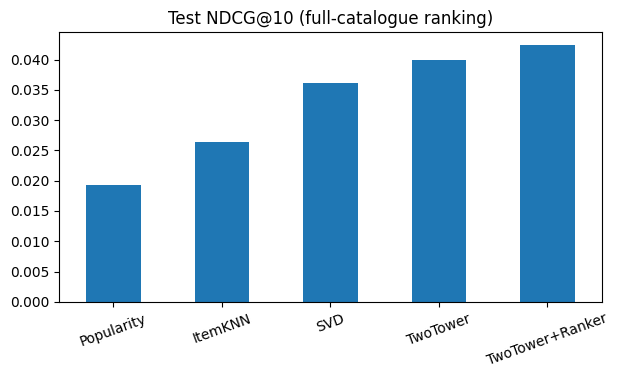

In [ ]:
res = pd.DataFrame({k: summarize(RANK[k], TOP[k]) for k in RANK}).T
res["NDCG@10 vs popularity"] = (res["NDCG@10"] / res.loc["Popularity","NDCG@10"] - 1).map(lambda x: f"{x:+.0%}")
display(res.round(4)); res.to_csv("artifacts/results.csv")
res["NDCG@10"].plot.bar(title="Test NDCG@10 (full-catalogue ranking)", figsize=(7,3.5)); plt.xticks(rotation=20); plt.show()

12: cold-start and long-tail slices

{'>60': 2863, '26-60': 1656, '11-25': 1285, '<=10': 230}


,<=10,11-25,26-60,>60
Popularity,0.0308,0.0267,0.0172,0.0162
ItemKNN,0.0452,0.0441,0.0234,0.0185
SVD,0.0506,0.0687,0.0370,0.0197
TwoTower,0.0875,0.0638,0.0454,0.0221
TwoTower+Ranker,0.0931,0.0674,0.0393,0.0289


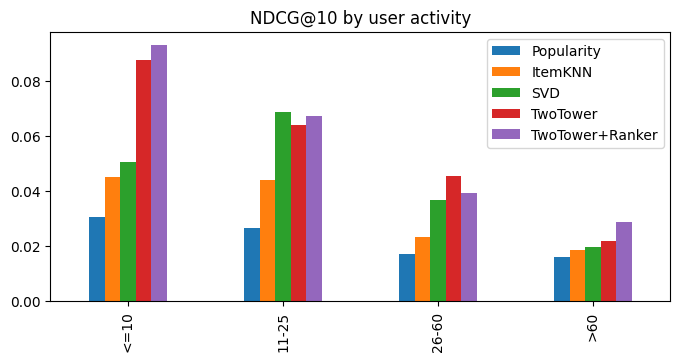

,tail,mid,head
Popularity,0.0000,0.0000,0.0578
ItemKNN,0.0000,0.0008,0.0781
SVD,0.0004,0.0165,0.0912
TwoTower,0.0101,0.0277,0.0817
TwoTower+Ranker,0.0103,0.0249,0.0920


In [ ]:
bins = ["<=10", "11-25", "26-60", ">60"]
ub = np.array(pd.cut(user_n, [0,10,25,60,np.inf], labels=bins), dtype=str)
print(pd.Series(ub).value_counts().to_dict())
cold = pd.DataFrame({n: pd.Series(ndcg_vec(r)).groupby(ub).mean() for n, r in RANK.items()}).loc[bins].T
display(cold.round(4)); cold.T.plot.bar(figsize=(8,3.5), title="NDCG@10 by user activity"); plt.show()

tb = np.array(pd.qcut(pd.Series(item_cnt[test_target]).rank(method="first"), 3, labels=["tail","mid","head"]), dtype=str)
tail = pd.DataFrame({n: pd.Series(ndcg_vec(r)).groupby(tb).mean() for n, r in RANK.items()}).loc[["tail","mid","head"]].T
display(tail.round(4))

13: simulated A/B test

In [ ]:
from scipy.stats import norm
hitA = (RANK["SVD"] < 10).astype(float); hitB = (RANK["TwoTower+Ranker"] < 10).astype(float)
assign = np.random.default_rng(1).random(nU) < 0.5
a, b = hitA[assign], hitB[~assign]; pa, pb = a.mean(), b.mean()
se = np.sqrt(pa*(1-pa)/len(a) + pb*(1-pb)/len(b)); diff = pb - pa
print(f"[50/50 split] control={pa:.4f} treatment={pb:.4f} lift={diff/pa:+.1%} "
      f"95% CI=({diff-1.96*se:+.4f},{diff+1.96*se:+.4f}) p={2*(1-norm.cdf(abs(diff/se))):.4f}")

rng = np.random.default_rng(2); nA, nB = ndcg_vec(RANK["SVD"]), ndcg_vec(RANK["TwoTower+Ranker"])
boots = [nB[ix].mean() - nA[ix].mean() for ix in (rng.integers(0, nU, nU) for _ in range(2000))]
print("[paired bootstrap] NDCG@10 diff=%+.4f 95%% CI=(%+.4f,%+.4f)" % (nB.mean()-nA.mean(), *np.percentile(boots, [2.5, 97.5])))

def n_per_arm(p0, rel, alpha=0.05, power=0.8):
    z = norm.ppf(1-alpha/2) + norm.ppf(power); return int(np.ceil(2*z**2*p0*(1-p0)/(p0*rel)**2))
print("Users per arm to detect +5%% relative lift: %d" % n_per_arm(pa, 0.05))

[50/50 split] control=0.0764 treatment=0.0807 lift=+5.6% 95% CI=(-0.0093,+0.0179) p=0.5334
[paired bootstrap] NDCG@10 diff=+0.0063 95% CI=(+0.0024,+0.0102)
Users per arm to detect +5% relative lift: 75926


14: latency (single request, CPU)

In [ ]:
torch.set_num_threads(1)
cpu_model = TwoTower(nU, nI, dim=cfg["dim"]); cpu_model.load_state_dict({k: v.cpu() for k, v in model.state_dict().items()}); cpu_model.eval()
item_mat = embed_all(model)[1].cpu()
g_c, a_c, o_c = g_t.cpu(), a_t.cpu(), o_t.cpu()
seen_idx = [torch.tensor(np.where(seen_test_mask[u])[0]) for u in range(nU)]

def recommend_user(u, K=10):
    with torch.no_grad():
        uv = cpu_model.user_vec(torch.tensor([u]), g_c[u:u+1], a_c[u:u+1], o_c[u:u+1])
        s = (uv @ item_mat.T)[0]; s[seen_idx[u]] = -1e9
        return torch.topk(s, K).indices.numpy()

ts = []
for u in np.random.default_rng(0).integers(0, nU, 1000):
    t0 = time.perf_counter(); recommend_user(int(u)); ts.append((time.perf_counter()-t0)*1000)
print("p50=%.2f ms  p95=%.2f ms" % (np.percentile(ts, 50), np.percentile(ts, 95)))

p50=0.32 ms  p95=0.46 ms


15: fraud module (real Kaggle dataset)


Using Colab cache for faster access to the 'creditcardfraud' dataset.
train: 170884 rows, 360 frauds (0.2107%)
val: 56961 rows, 57 frauds (0.1001%)
test: 56962 rows, 75 frauds (0.1317%)
Random-guess PR-AUC = fraud rate in test = 0.0013


,PR_AUC,ROC_AUC,precision,recall,F1,alerts_per_10k,recall@0.5%_review
model,,,,,,,
LogReg,0.7472,0.9818,0.9608,0.6533,0.7778,8.9533,0.8533
LightGBM,0.7707,0.9604,0.9032,0.7467,0.8175,10.8844,0.7867


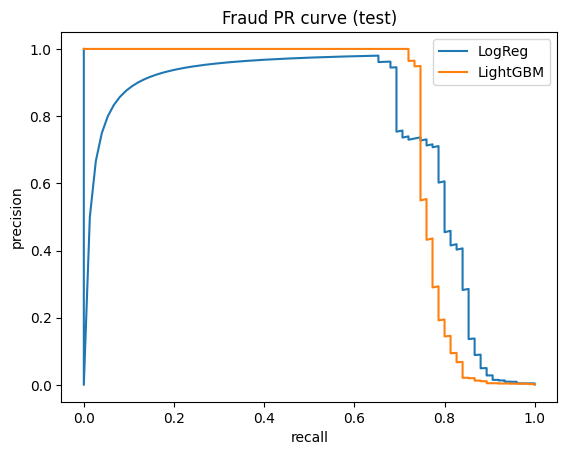

In [ ]:
import kagglehub
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score)

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
fraud = pd.read_csv(os.path.join(path, "creditcard.csv")).sort_values("Time").reset_index(drop=True)
fraud["LogAmount"] = np.log1p(fraud.Amount)
feat_cols = [c for c in fraud.columns if c not in ("Class", "Time", "Amount")]
n = len(fraud); a_, b_ = int(.6*n), int(.8*n)
tr, va, te = fraud.iloc[:a_], fraud.iloc[a_:b_], fraud.iloc[b_:]
for nm, d in [("train", tr), ("val", va), ("test", te)]:
    print(f"{nm}: {len(d)} rows, {int(d.Class.sum())} frauds ({d.Class.mean():.4%})")

lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)).fit(tr[feat_cols], tr.Class)
gbm = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.03, num_leaves=31, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.8, scale_pos_weight=min((tr.Class==0).sum()/tr.Class.sum(), 50),
                         metric="average_precision", random_state=SEED, verbose=-1)
gbm.fit(tr[feat_cols], tr.Class, eval_set=[(va[feat_cols], va.Class)], callbacks=[lgb.early_stopping(50, verbose=False)])

def best_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    return th[np.argmax(2*pr[:-1]*rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12))]

def fraud_report(name, p_val, p_te):
    t = best_threshold(va.Class, p_val); pred = p_te >= t
    top = np.argsort(-p_te)[:int(0.005*len(te))]                  # analysts review the riskiest 0.5%
    return {"model": name, "PR_AUC": average_precision_score(te.Class, p_te), "ROC_AUC": roc_auc_score(te.Class, p_te),
            "precision": precision_score(te.Class, pred, zero_division=0), "recall": recall_score(te.Class, pred),
            "F1": f1_score(te.Class, pred), "alerts_per_10k": pred.mean()*1e4,
            "recall@0.5%_review": te.Class.values[top].sum()/te.Class.sum()}

P = {"LogReg": (lr.predict_proba(va[feat_cols])[:,1], lr.predict_proba(te[feat_cols])[:,1]),
     "LightGBM": (gbm.predict_proba(va[feat_cols])[:,1], gbm.predict_proba(te[feat_cols])[:,1])}
fr = pd.DataFrame([fraud_report(k, *v) for k, v in P.items()]).set_index("model")
print("Random-guess PR-AUC = fraud rate in test = %.4f" % te.Class.mean())
display(fr.round(4)); fr.to_csv("artifacts/fraud_results.csv")
for k, (_, pt) in P.items():
    pr, rc, _ = precision_recall_curve(te.Class, pt); plt.plot(rc, pr, label=k)
plt.xlabel("recall"); plt.ylabel("precision"); plt.legend(); plt.title("Fraud PR curve (test)"); plt.show()